In [4]:
import random
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np

In [5]:
# Set random seed for reproducibility

my_seed = 334  # 42. 2135. 334. 191
my_seed = 415


parameters = {
    "annealing_temp": [40, 55, 70, 80, 90, 100, 110, 120, 135, 150],  # °C
    "annealing_time": [
        60,
        120,
        180,
        240,
        300,
        420,
        540,
        720,
        900,
        1200,
        1500,
        1800,
    ],  # sec
    "dispense_volume": [25, 50, 75, 100, 125, 150, 200, 300],  # uL
    "spin_speed": [1000, 2000, 3000, 4000, 5000, 6000],  # rpm
    "dispense_speed": [80, 100, 120, 140, 160, 180, 200, 220, 240],  # uL/s
    "concentration": [0.1, 0.5, 1.0, 1.5, 2.0],  # M
}

parameters = {
    "annealing_temp": [55, 70, 90, 110, 135, 150],  # °C
    "annealing_time": [
        60,
        180,
        300,
        420,
        540,
        720,
        900,
    ],  # sec
    "dispense_volume": [
        50,
        75,
        100,
        125,
        150,
    ],  # uL
    "spin_speed": [1000, 2000, 3000, 4000, 5000, 6000],  # rpm
    "dispense_speed": [80, 100, 120, 140, 160, 180, 200, 220, 240],  # uL/s
    "concentration": [0.25, 0.5, 1.0, 1.5],  # M
}


def generate_and_save_samples(n=8, json_filename="parameter_samples.json", seed=None):
    if seed is None:
        seed = random.randint(0, 9999)

    rs = np.random.RandomState(seed)

    # Generate random samples
    samples = [
        {param: rs.choice(values) for param, values in parameters.items()}
        for _ in range(n)
    ]

    # Convert to DataFrame and sort by annealing_time
    samples_df = pd.DataFrame(samples)
    samples_df.loc[0 : (n / 2 - 1), "a_site"] = "MBAI"
    samples_df.loc[(n / 2) : n, "a_site"] = "ClMBAI"

    # samples_df = samples_df.sort_values(by="annealing_time", ascending=False)

    json_filename = f"parameter_samples_{seed:04d}.json"

    # Save as JSON in list of dictionaries format
    with open(json_filename, "w") as json_file:
        json.dump(samples_df.to_dict(orient="records"), json_file, indent=2)

    # Create recipe, which is the samples_df repeated 3 times
    recipe = pd.concat([samples_df] * 3, ignore_index=True)
    recipe_filename = f"parameter_{seed:04d}_recipes.json"
    with open(recipe_filename, "w") as recipe_file:
        json.dump(recipe.to_dict(orient="records"), recipe_file, indent=2)

    print(f"Generated {n} random samples:")
    print(f"- Saved to JSON: {json_filename}")

    return samples


# Generate 8 random samples and save in both formats
samples = generate_and_save_samples(32, seed=my_seed)

# Print the samples for verification
print("\nGenerated samples:")
for i, sample in enumerate(samples, 1):
    print(f"Sample {i}: {sample}")

pd.DataFrame(samples)

Generated 32 random samples:
- Saved to JSON: parameter_samples_0415.json

Generated samples:
Sample 1: {'annealing_temp': np.int64(70), 'annealing_time': np.int64(300), 'dispense_volume': np.int64(100), 'spin_speed': np.int64(4000), 'dispense_speed': np.int64(220), 'concentration': np.float64(0.25)}
Sample 2: {'annealing_temp': np.int64(70), 'annealing_time': np.int64(60), 'dispense_volume': np.int64(75), 'spin_speed': np.int64(6000), 'dispense_speed': np.int64(140), 'concentration': np.float64(0.5)}
Sample 3: {'annealing_temp': np.int64(110), 'annealing_time': np.int64(540), 'dispense_volume': np.int64(150), 'spin_speed': np.int64(5000), 'dispense_speed': np.int64(180), 'concentration': np.float64(1.0)}
Sample 4: {'annealing_temp': np.int64(135), 'annealing_time': np.int64(900), 'dispense_volume': np.int64(125), 'spin_speed': np.int64(2000), 'dispense_speed': np.int64(220), 'concentration': np.float64(0.25)}
Sample 5: {'annealing_temp': np.int64(135), 'annealing_time': np.int64(720),

,annealing_temp,annealing_time,dispense_volume,spin_speed,dispense_speed,concentration
0,70,300,100,4000,220,0.25
1,70,60,75,6000,140,0.50
2,110,540,150,5000,180,1.00
3,135,900,125,2000,220,0.25
4,135,720,150,4000,100,1.00
5,135,540,100,1000,180,1.50
6,90,900,75,1000,160,0.50
7,70,180,125,1000,120,1.50
8,70,420,125,4000,200,1.00
9,110,420,75,6000,240,0.50


['annealing_temp' 'annealing_time' 'dispense_volume' 'spin_speed'
 'dispense_speed' 'concentration']


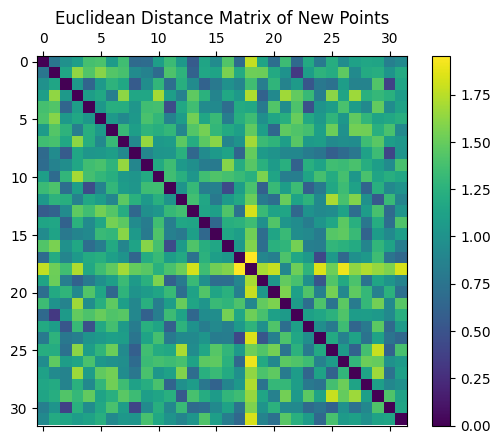

In [8]:
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import MinMaxScaler

# Calculate pairwise distances
data = pd.DataFrame(samples)

# Normalize the data for better distance measurement
scaler = MinMaxScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)
print(scaler.get_feature_names_out())

distances = pdist(data_scaled.values, metric="euclidean")
distance_matrix = squareform(distances)
fig, ax = plt.subplots()
cax = ax.matshow(distance_matrix, cmap="viridis")
fig.colorbar(cax)
ax.set_title("Euclidean Distance Matrix of New Points")
plt.show()

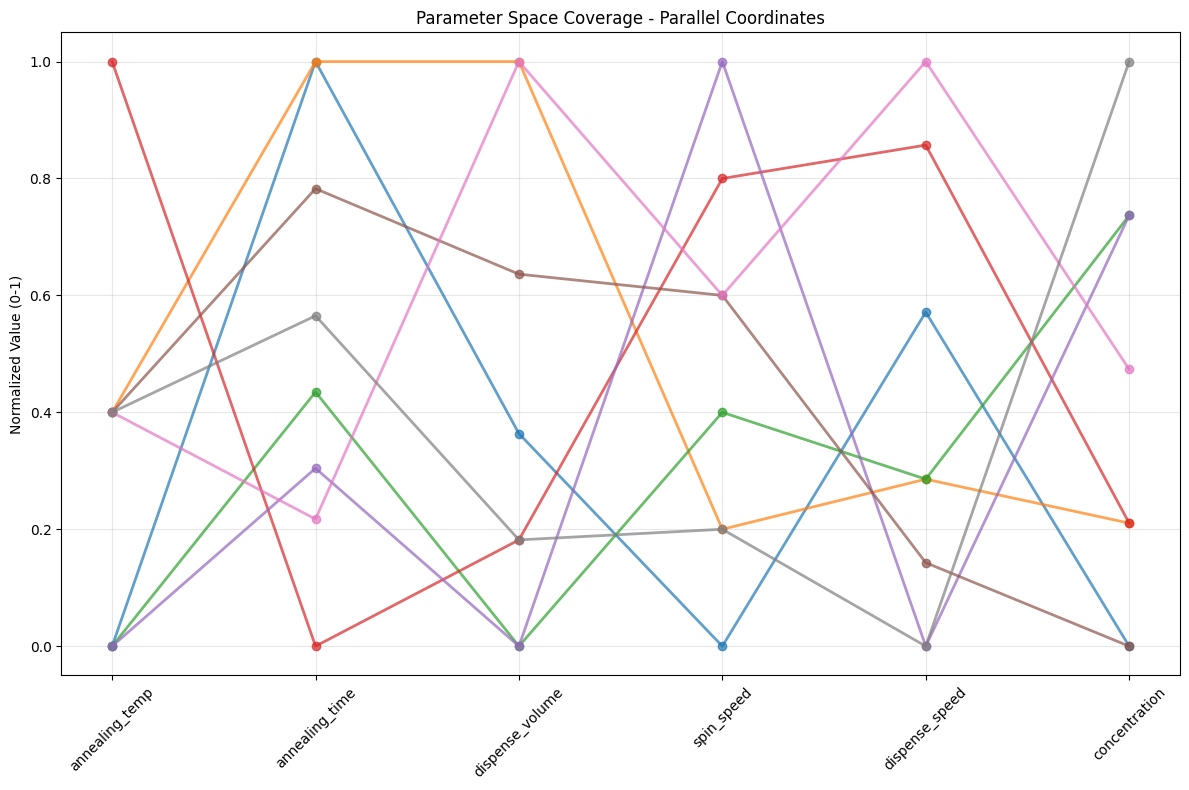

In [20]:
# Load the data
df = pd.read_json("parameter_samples_0410.json")


# 3. Parallel Coordinates Plot
plt.figure(figsize=(12, 8))

# Normalize the data
df_norm = df.copy()
for col in df.columns:
    df_norm[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

# Plot each sample as a line
for i in range(len(df_norm)):
    plt.plot(range(len(df.columns)), df_norm.iloc[i], "o-", alpha=0.7, linewidth=2)

plt.xticks(range(len(df.columns)), df.columns, rotation=45)
plt.ylabel("Normalized Value (0-1)")
plt.title("Parameter Space Coverage - Parallel Coordinates")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()